 Male Strength — analiza


 1. Učitavanje i formiranje dataseta

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import kagglehub

from kagglehub import KaggleDatasetAdapter

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "valakhorasani/gym-members-exercise-dataset",
    "gym_members_exercise_tracking.csv"
)

print("Dimenzije celog dataseta:", df.shape)

/Users/brankomitic/DataspellProjects/alternativni_dataset_diplomski/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/28/tt6vttm91r1c29lt4s1fr9z40000gn/T/ipykernel_1347/904456173.py:9: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Dimenzije celog dataseta: (973, 15)


In [2]:
male_strength = df[
    (df["Gender"] == "Male") &
    (df["Workout_Type"] == "Strength")
].copy()

print("Dimenzije Male Strength podskupa:", male_strength.shape)

male_strength.head()

Dimenzije Male Strength podskupa: (135, 15)


,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
3,25,Male,53.2,1.70,190,164,56,0.59,532.0,Strength,28.8,2.1,3,1,18.41
4,38,Male,46.1,1.79,188,158,68,0.64,556.0,Strength,29.2,2.8,3,1,14.39
8,28,Male,121.7,1.94,185,127,52,1.03,719.0,Strength,28.9,2.6,4,2,32.34
20,19,Male,89.0,1.77,175,127,72,1.50,1048.0,Strength,28.9,3.7,4,2,28.41
27,59,Male,53.9,1.75,168,135,69,1.48,989.0,Strength,21.6,2.8,4,2,17.60


2.Priprema podataka


In [3]:
print("Broj nedostajućih vrednosti po atributima:")
print(male_strength.isnull().sum())

print("\nUkupan broj nedostajućih vrednosti:")
print(male_strength.isnull().sum().sum())
#nema nan vrednosti,tu nista

Broj nedostajućih vrednosti po atributima:
Age                              0
Gender                           0
Weight (kg)                      0
Height (m)                       0
Max_BPM                          0
Avg_BPM                          0
Resting_BPM                      0
Session_Duration (hours)         0
Calories_Burned                  0
Workout_Type                     0
Fat_Percentage                   0
Water_Intake (liters)            0
Workout_Frequency (days/week)    0
Experience_Level                 0
BMI                              0
dtype: int64

Ukupan broj nedostajućih vrednosti:
0


In [4]:
### 2.2. Analiza korelacija

#Analiziraju se korelacije između numeričkih atributa kako bi se identifikovale promenljive sa visokom međusobnom korelacijom (|r| > 0.7).

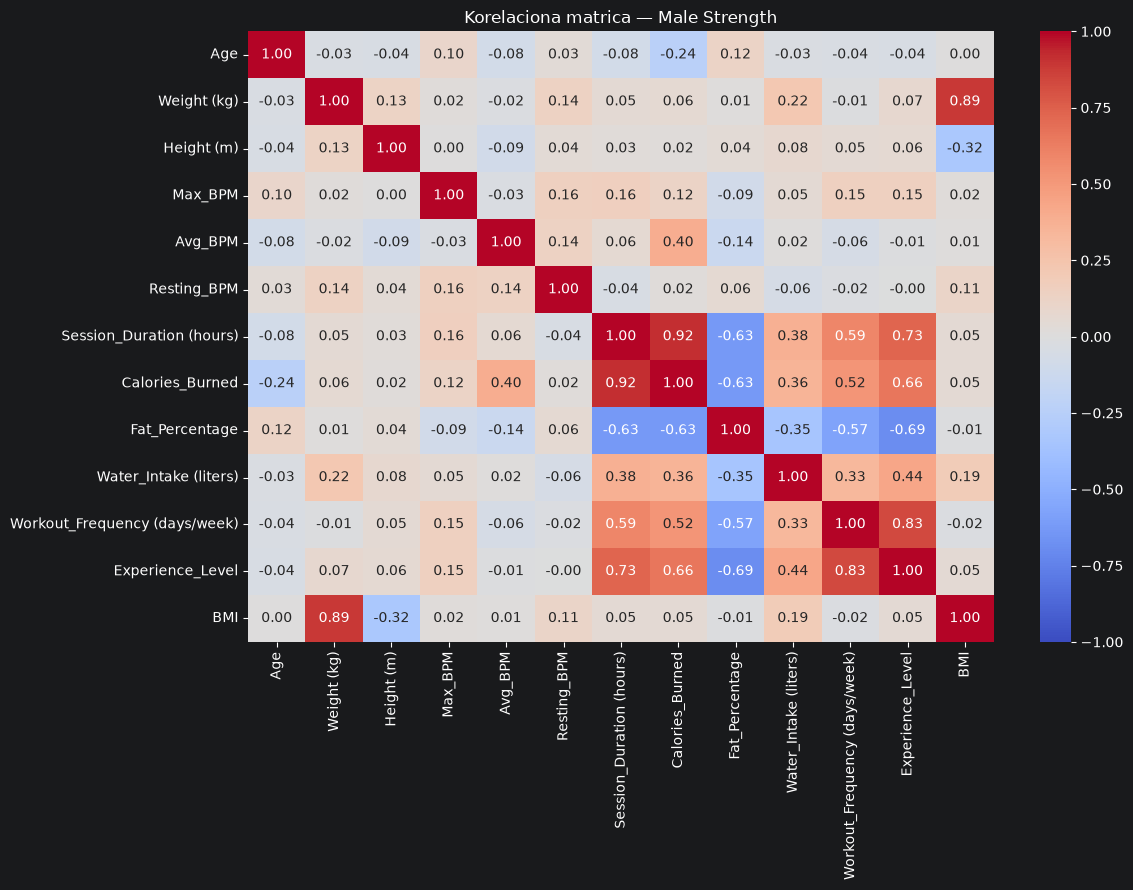

In [5]:
numeric_df = male_strength.select_dtypes(include=np.number)

corr_matrix = numeric_df.corr()

plt.figure(figsize=(12, 9))

sb.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Korelaciona matrica — Male Strength")
plt.tight_layout()
plt.show()

In [6]:
print("Korelacije veće od 0.7:")

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        corr = corr_matrix.iloc[i, j]

        if abs(corr) > 0.7:
            print(
                f"{corr_matrix.columns[i]} - "
                f"{corr_matrix.columns[j]}: {corr:.4f}"
            )

Korelacije veće od 0.7:
Weight (kg) - BMI: 0.8891
Session_Duration (hours) - Calories_Burned: 0.9199
Session_Duration (hours) - Experience_Level: 0.7271
Workout_Frequency (days/week) - Experience_Level: 0.8318


In [7]:
#Izbacujemo experience level,BMI i calories burned,zadrzavamo session duration.

In [8]:
features = [
    'Age',
    'Weight (kg)',
    'Height (m)',
    'Max_BPM',
    'Avg_BPM',
    'Resting_BPM',
    'Session_Duration (hours)',
    'Fat_Percentage',
    'Water_Intake (liters)',
    'Workout_Frequency (days/week)'
]

X = male_strength[features].copy()

print("Broj atributa:", X.shape[1])
print("Dimenzije:", X.shape)

Broj atributa: 10
Dimenzije: (135, 10)


### 2.3. Analiza outliera

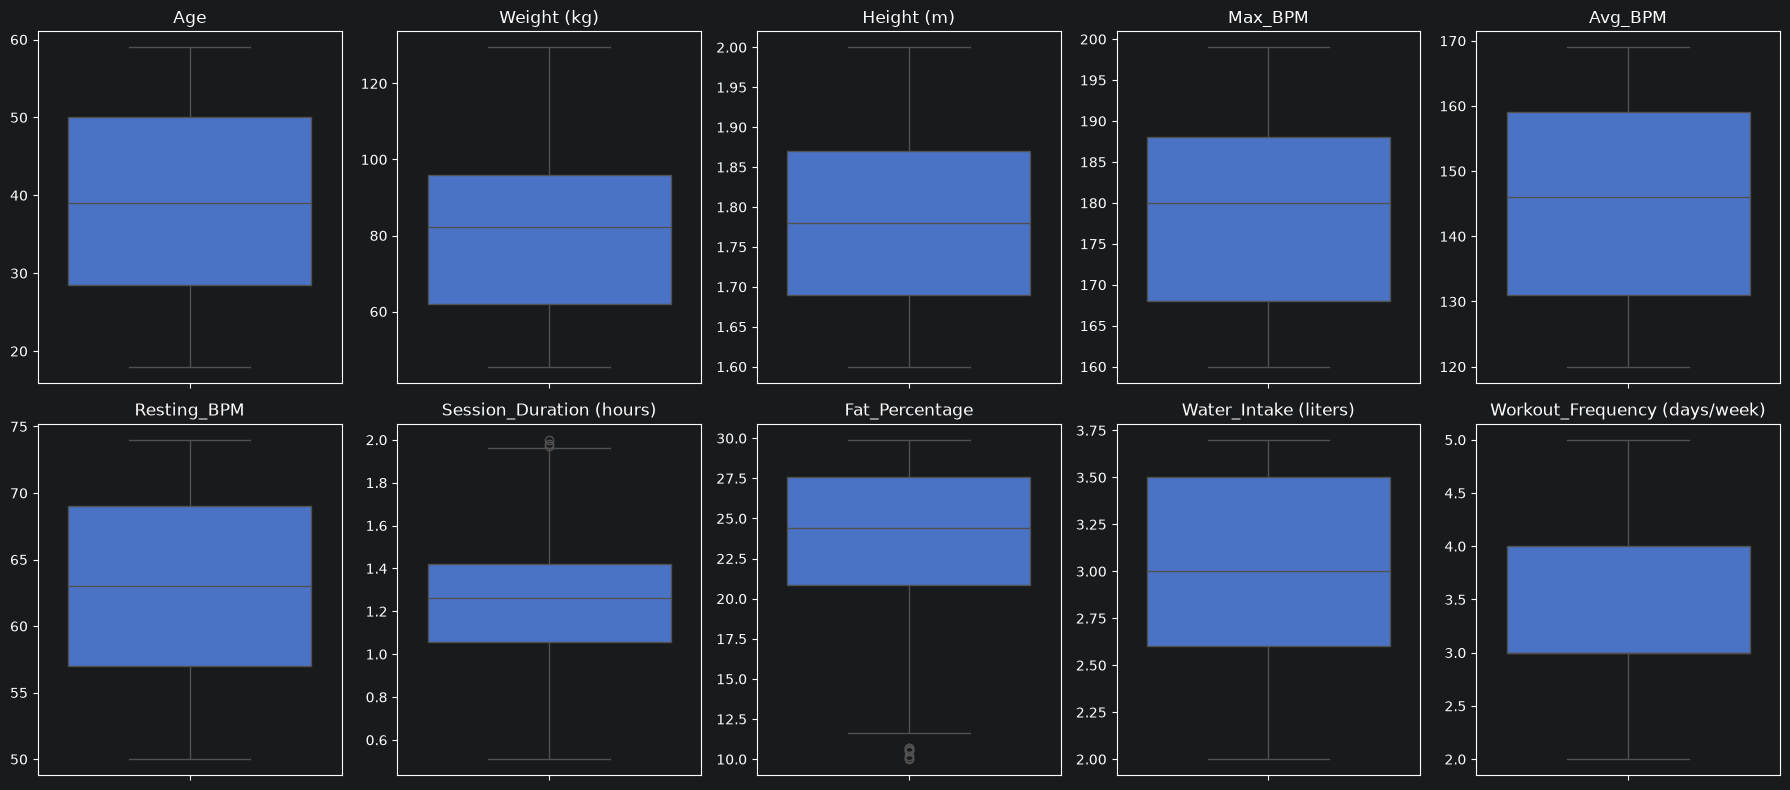

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for ax, col in zip(axes.flatten(), features):
    sb.boxplot(y=X[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

In [10]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_lower = X.lt(lower_bound).sum()
outliers_upper = X.gt(upper_bound).sum()

outliers_summary = pd.DataFrame({
    'Donji outlieri': outliers_lower,
    'Gornji outlieri': outliers_upper,
    'Ukupno': outliers_lower + outliers_upper
})

print(outliers_summary)

                               Donji outlieri  Gornji outlieri  Ukupno
Age                                         0                0       0
Weight (kg)                                 0                0       0
Height (m)                                  0                0       0
Max_BPM                                     0                0       0
Avg_BPM                                     0                0       0
Resting_BPM                                 0                0       0
Session_Duration (hours)                    0                3       3
Fat_Percentage                              8                0       8
Water_Intake (liters)                       0                0       0
Workout_Frequency (days/week)               0                0       0


In [11]:
#Session duration ima 3 gornja outliera a fat percentage ima 8 donjih outliera

In [12]:
#Sad cemo da testiramo granice i vidimo gde nestaju outlieri
from scipy.stats.mstats import winsorize

for col, side in [
    ('Session_Duration (hours)', 'upper'),
    ('Fat_Percentage', 'lower')
]:
    print(f"\n{col}")

    for limit in [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08]:
        lower_limit = limit if side == 'lower' else 0
        upper_limit = limit if side == 'upper' else 0

        values = np.asarray(
            winsorize(
                X[col].to_numpy().copy(),
                limits=(lower_limit, upper_limit)
            )
        )

        Q1 = np.percentile(values, 25)
        Q3 = np.percentile(values, 75)
        IQR = Q3 - Q1

        n_outliers = (
            (values < Q1 - 1.5 * IQR) |
            (values > Q3 + 1.5 * IQR)
        ).sum()

        print(f"Limit {limit:.2f}: {n_outliers} outliera")


Session_Duration (hours)
Limit 0.01: 3 outliera
Limit 0.02: 3 outliera
Limit 0.03: 0 outliera
Limit 0.04: 0 outliera
Limit 0.05: 0 outliera
Limit 0.06: 0 outliera
Limit 0.07: 0 outliera
Limit 0.08: 0 outliera

Fat_Percentage
Limit 0.01: 8 outliera
Limit 0.02: 8 outliera
Limit 0.03: 8 outliera
Limit 0.04: 8 outliera
Limit 0.05: 8 outliera
Limit 0.06: 0 outliera
Limit 0.07: 0 outliera
Limit 0.08: 0 outliera


In [13]:
#Vidimo da za session duration nestaju outlieri kod limit 0.03 a kod fat_percentage kod 0.06
from scipy.stats.mstats import winsorize

X_wins = X.copy()

X_wins['Session_Duration (hours)'] = np.asarray(
    winsorize(
        X['Session_Duration (hours)'].to_numpy().copy(),
        limits=(0, 0.03)
    )
)

X_wins['Fat_Percentage'] = np.asarray(
    winsorize(
        X['Fat_Percentage'].to_numpy().copy(),
        limits=(0.06, 0)
    )
)

In [14]:
#Ponovna provera za outliere nakon winsorizacije
Q1 = X_wins.quantile(0.25)
Q3 = X_wins.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Broj preostalih outliera po atributima:")
print(((X_wins.lt(lower)) | (X_wins.gt(upper))).sum())

Broj preostalih outliera po atributima:
Age                              0
Weight (kg)                      0
Height (m)                       0
Max_BPM                          0
Avg_BPM                          0
Resting_BPM                      0
Session_Duration (hours)         0
Fat_Percentage                   0
Water_Intake (liters)            0
Workout_Frequency (days/week)    0
dtype: int64


### 2.4. Skaliranje podataka

Koristicemo minmax scaler da svi budu na 0 do 1 granici

In [15]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_wins),
    columns=X_wins.columns,
    index=X_wins.index
)

print("Dimenzije skaliranog skupa:", X_scaled.shape)

X_scaled.head()

Dimenzije skaliranog skupa: (135, 10)


,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week)
3,0.170732,0.091667,0.250,0.769231,0.897959,0.250000,0.055172,0.939891,0.058824,0.333333
4,0.487805,0.007143,0.475,0.717949,0.775510,0.750000,0.089655,0.961749,0.470588,0.333333
8,0.243902,0.907143,0.850,0.641026,0.142857,0.083333,0.358621,0.945355,0.352941,0.666667
20,0.024390,0.517857,0.425,0.384615,0.142857,0.916667,0.682759,0.945355,1.000000,0.666667
27,1.000000,0.100000,0.375,0.205128,0.306122,0.791667,0.668966,0.546448,0.470588,0.666667


In [16]:
print("Minimalne vrednosti:")
print(X_scaled.min().round(2))

print("\nMaksimalne vrednosti:")
print(X_scaled.max().round(2))

Minimalne vrednosti:
Age                              0.0
Weight (kg)                      0.0
Height (m)                       0.0
Max_BPM                          0.0
Avg_BPM                          0.0
Resting_BPM                      0.0
Session_Duration (hours)         0.0
Fat_Percentage                   0.0
Water_Intake (liters)            0.0
Workout_Frequency (days/week)    0.0
dtype: float64

Maksimalne vrednosti:
Age                              1.0
Weight (kg)                      1.0
Height (m)                       1.0
Max_BPM                          1.0
Avg_BPM                          1.0
Resting_BPM                      1.0
Session_Duration (hours)         1.0
Fat_Percentage                   1.0
Water_Intake (liters)            1.0
Workout_Frequency (days/week)    1.0
dtype: float64


In [17]:
#Sve vrednosti su od 0 do 1

In [ ]:
## 3. Određivanje optimalnog broja klastera (K)

### 3.1. Elbow metoda

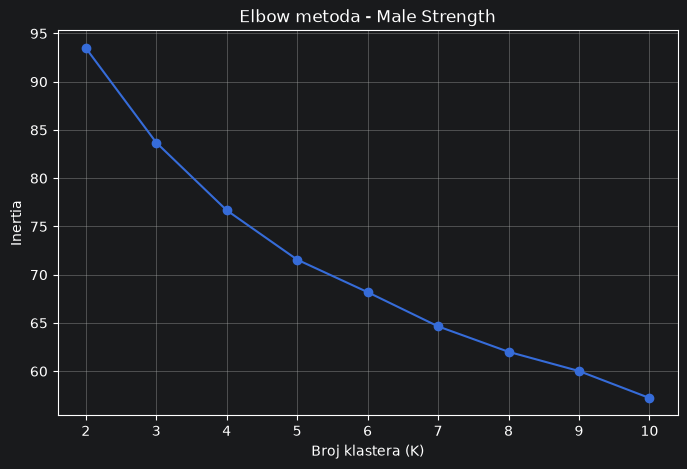

K=2: Inertia=93.4951
K=3: Inertia=83.6936
K=4: Inertia=76.6751
K=5: Inertia=71.5612
K=6: Inertia=68.1922
K=7: Inertia=64.6474
K=8: Inertia=62.0106
K=9: Inertia=60.0182
K=10: Inertia=57.2242


In [19]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o')
plt.xlabel('Broj klastera (K)')
plt.ylabel('Inertia')
plt.title('Elbow metoda - Male Strength')
plt.xticks(K_range)
plt.grid(True)
plt.show()
for k, value in zip(K_range, inertia):
    print(f"K={k}: Inertia={value:.4f}")

In [17]:
#Ne viidmo jasno gde je najveci pad pa onda silhouette metoda treba da nam razresi to

In [17]:
### 3.2. Silhouette metoda

K=2: Silhouette=0.2220
K=3: Silhouette=0.1428
K=4: Silhouette=0.1426
K=5: Silhouette=0.1430
K=6: Silhouette=0.1328
K=7: Silhouette=0.1266
K=8: Silhouette=0.1343
K=9: Silhouette=0.1161
K=10: Silhouette=0.1324


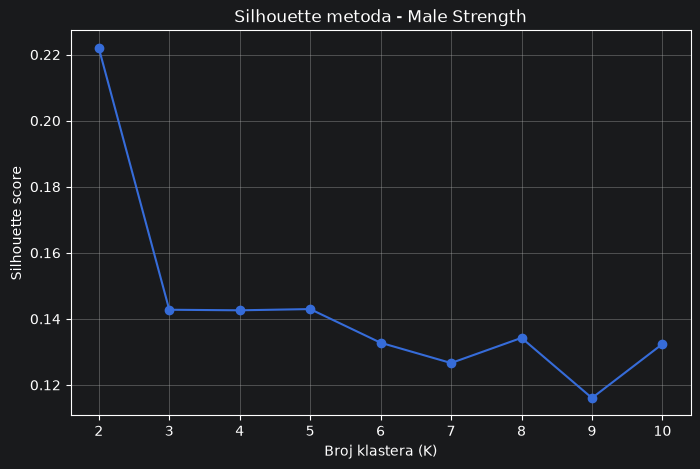

In [20]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f"K={k}: Silhouette={score:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel('Broj klastera (K)')
plt.ylabel('Silhouette score')
plt.title('Silhouette metoda - Male Strength')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [ ]:
#Na osonovu silhouette score se jasno vidi da je k=2 najbolji izbor, s toga uzimamo njega za klasterizaciju

In [21]:
print("Oblik X_scaled:", X_scaled.shape)

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)

print("\nBroj instanci po klasterima:")
print(pd.Series(labels).value_counts().sort_index())

Oblik X_scaled: (135, 10)

Broj instanci po klasterima:
0     23
1    112
Name: count, dtype: int64


In [ ]:
### 3.3. Dendrogrami

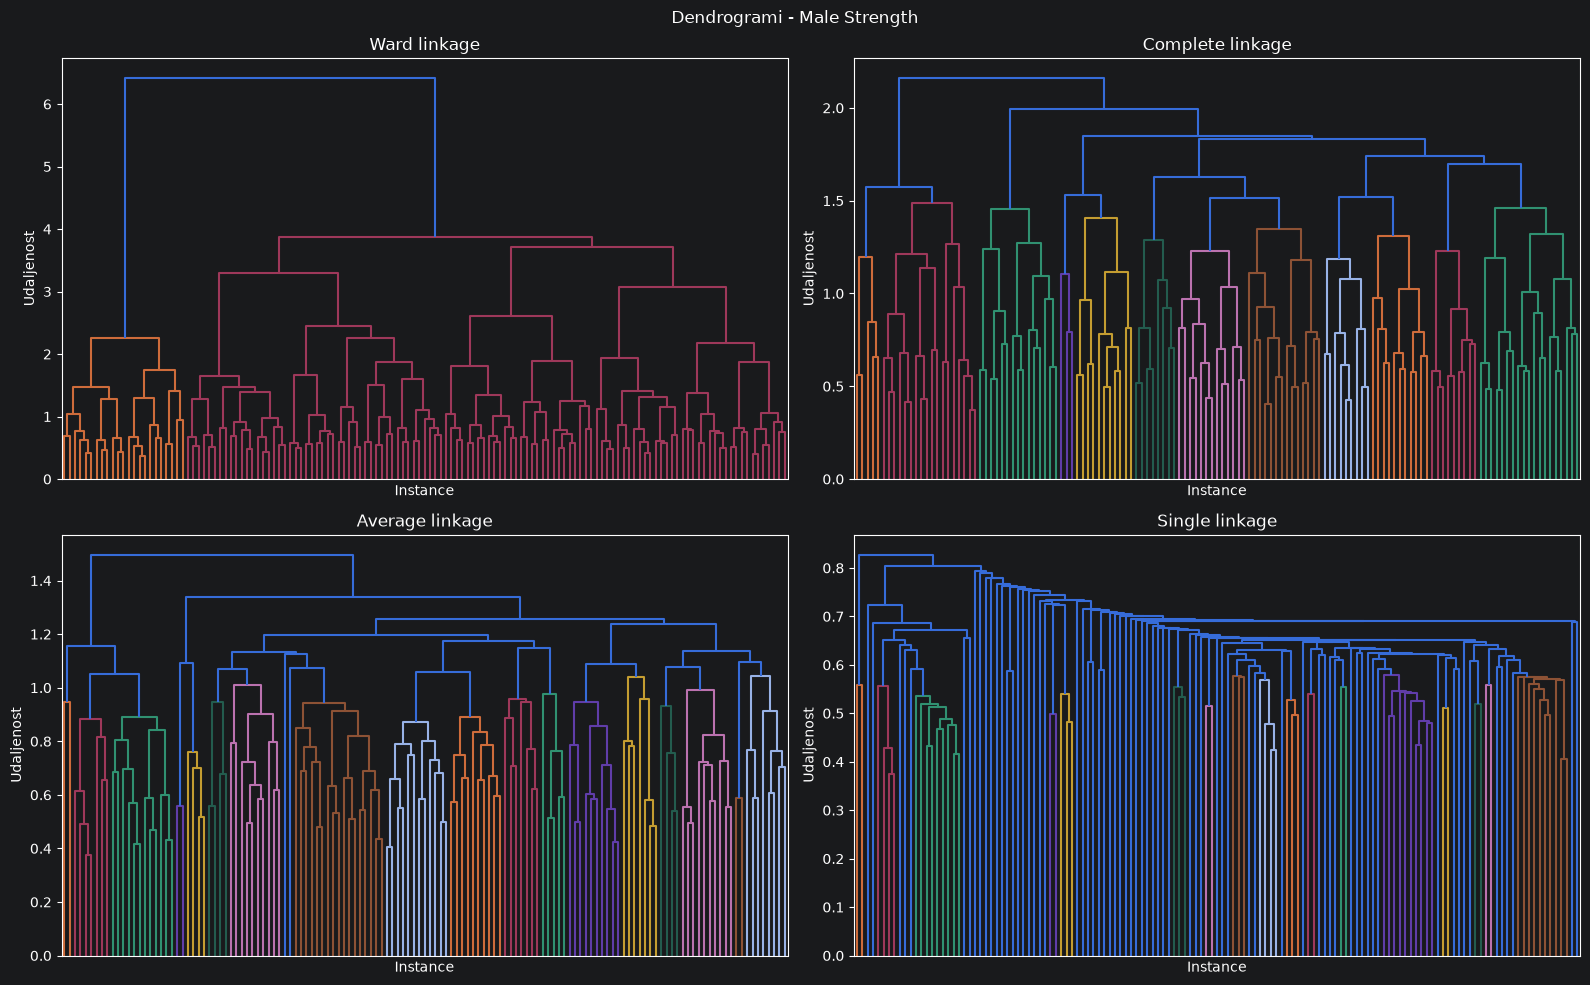

In [22]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

methods = ['ward', 'complete', 'average', 'single']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, method in zip(axes.flatten(), methods):
    Z = linkage(X_scaled, method=method)

    dendrogram(
        Z,
        ax=ax,
        no_labels=True
    )

    ax.set_title(f'{method.capitalize()} linkage')
    ax.set_xlabel('Instance')
    ax.set_ylabel('Udaljenost')

plt.suptitle('Dendrogrami - Male Strength')
plt.tight_layout()
plt.show()

In [ ]:
#Vidimo da ward metoda jasno sugerise 2 klastera,ostale mesovito

In [ ]:
## 4. Klasterizacija i tumačenje klastera

### 4.1. KMeans klasterizacija i tumačenje klastera

In [24]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

df_kmeans = male_strength.copy()

df_kmeans['Cluster'] = kmeans.fit_predict(X_scaled)

print("Broj instanci po klasterima:")
print(df_kmeans['Cluster'].value_counts().sort_index())

print("\nProsečne vrednosti atributa po klasterima:")
display(
    df_kmeans.groupby('Cluster')[features + ['Calories_Burned']]
    .mean()
    .round(2)
)

Broj instanci po klasterima:
Cluster
0     23
1    112
Name: count, dtype: int64

Prosečne vrednosti atributa po klasterima:


,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Calories_Burned
Cluster,,,,,,,,,,,
0,35.70,85.53,1.80,181.35,149.52,61.83,1.79,12.29,3.50,4.61,1425.00
1,39.86,81.34,1.78,178.54,144.46,63.15,1.14,25.22,2.88,3.13,857.36


In [17]:
#Klaster 0 ima 23 instance,mnogo manje od klastera 1 i ima duze treninge, vecu ucestalost treniranja, nizi procenat telesne masti i veću prosecnu potrosnju kalorija.Dok klaster 1 sa 112 instanci ima krace i redje treninge visi procenat telesne masti i nizu prosecnu potrosnju kalorija

In [17]:
### 4.2. Hijerarhijska klasterizacija i tumačenje klastera

In [25]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

methods = ['ward', 'complete', 'average', 'single']

for method in methods:
    model = AgglomerativeClustering(
        n_clusters=2,
        linkage=method
    )

    labels = model.fit_predict(X_scaled)

    print(f"\n===== {method.upper()} =====")

    print("Broj instanci po klasterima:")
    print(pd.Series(labels).value_counts().sort_index())

    print("Silhouette score:",
          round(silhouette_score(X_scaled, labels), 4))


===== WARD =====
Broj instanci po klasterima:
0    112
1     23
Name: count, dtype: int64
Silhouette score: 0.222

===== COMPLETE =====
Broj instanci po klasterima:
0    112
1     23
Name: count, dtype: int64
Silhouette score: 0.222

===== AVERAGE =====
Broj instanci po klasterima:
0    114
1     21
Name: count, dtype: int64
Silhouette score: 0.2137

===== SINGLE =====
Broj instanci po klasterima:
0    133
1      2
Name: count, dtype: int64
Silhouette score: 0.0937


In [ ]:
#Ward i average imaju isti silhouette score pa je svejedno koji koristimo al iz prakticnih razloga koristicemo Ward

In [27]:
model = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

df_hierarchical = male_strength.copy()

df_hierarchical['Cluster'] = model.fit_predict(X_scaled)

print("Broj instanci po klasterima:")
print(df_hierarchical['Cluster'].value_counts().sort_index())

print("\nProsečne vrednosti atributa po klasterima:")
display(
    df_hierarchical.groupby('Cluster')[features + ['Calories_Burned']]
    .mean()
    .round(2)
)

Broj instanci po klasterima:
Cluster
0    112
1     23
Name: count, dtype: int64

Prosečne vrednosti atributa po klasterima:


,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Calories_Burned
Cluster,,,,,,,,,,,
0,39.86,81.34,1.78,178.54,144.46,63.15,1.14,25.22,2.88,3.13,857.36
1,35.70,85.53,1.80,181.35,149.52,61.83,1.79,12.29,3.50,4.61,1425.00


In [ ]:
#Imamo jako slicne rezultate ko u Kmeans sa aktivnijim klasterom nizi procenat masti,veca potrosnja kalorija itd, i ne tolko aktivan klaster sa vecim procentom masti nizom potrosnjom kalorija...

In [ ]:
ad